# Notebook 06: Prescriptive Optimisation Prototype

## 6.1 Introduction

This notebook develops the initial prescriptive analytics component of the project, *A Machine Learning–Driven Framework for Predicting Weekly Actual Production Quantity and Prescriptive Optimisation of Production Targets in the Shoe Manufacturing Division of DI Leather*.

Phase 1 predicts actual production quantity (`actual_qty`) from operational and product-related input variables. Phase 2 builds on that prediction capability to investigate alternative operational configurations that may help achieve a specified planned production quantity.

The saved Voting Ensemble model from Notebook 04 is reused as the production prediction engine. Candidate combinations of workers, working hours, and machines are evaluated using the saved model, and the resulting predictions are compared with the planned quantity.

This notebook implements a prototype of the prescriptive process. It does not retrain the prediction model or automatically change production operations.

## 6.1.1 Objectives

The objectives of this notebook are:

1. Load the final production prediction model.
2. Prepare a valid baseline input using an existing historical record.
3. Predict baseline actual production quantity.
4. Compare predicted production with a separately specified planned quantity.
5. Classify the baseline as underproduction, within tolerance, or overproduction.
6. Generate alternative combinations of workers, working hours, and machines.
7. Predict the production quantity associated with each candidate.
8. Rank candidate configurations according to target closeness and resource use.
9. Export the resulting scenario comparisons for further analysis.

The target variable remains `actual_qty`. The planned quantity is used for comparison and optimisation, not as an input to the saved prediction model.

In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from itertools import product
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 6.3 Loading the Saved Prediction Model

The final fitted Voting Ensemble pipeline from Notebook 04 is loaded from `models/production_model.joblib`.

The pipeline includes the preprocessing transformations and trained ensemble. Reusing it ensures that candidate inputs are processed consistently with the Phase 1 model.

The processed feature dataset is also loaded to establish a baseline from a real historical observation. This avoids inventing product categories or arbitrary baseline values.

In [2]:
# Locate the project root.
possible_roots = [
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd().parent.parent
]

project_root = None

for folder in possible_roots:
    model_file = folder / "models" / "production_model.joblib"
    data_file = folder / "data" / "processed" / "final_features.csv"

    if model_file.exists() and data_file.exists():
        project_root = folder
        break

if project_root is None:
    raise FileNotFoundError(
        "Project root not found. Check the notebook location "
        "and confirm that models/production_model.joblib and "
        "data/processed/final_features.csv exist."
    )

model_path = project_root / "models" / "production_model.joblib"
data_path = project_root / "data" / "processed" / "final_features.csv"

production_model = joblib.load(model_path)
df = pd.read_csv(data_path)

print("Saved production model loaded successfully.")
print("Project root:", project_root)
print("Model path:", model_path)
print("Dataset shape:", df.shape)

display(df.head())

Saved production model loaded successfully.
Project root: c:\Production-DI Leather\production-DI
Model path: c:\Production-DI Leather\production-DI\models\production_model.joblib
Dataset shape: (9495, 18)


,week_start_date,financial_month,week_no,week_of_month,factory_unit,product_family,item_name,size_id,grade,rate,no_of_workers,working_hours,machine_count,bottleneck_flag,order_category,machine_worker_ratio,avg_hours_per_worker,actual_qty
0,2022-04-18,Apr,3,3,Factory Unit 01,Ladies,BINOLI (VAST) - BROWN,12,A,4363.35,15,647.82,5,1,Others,0.333333,43.188000,38
1,2022-04-18,Apr,3,3,Factory Unit 01,Gents,RITHU 02 - L - BLUE,12,A,4223.86,20,855.19,6,1,Others,0.300000,42.759500,41
2,2022-04-18,Apr,3,3,Factory Unit 01,Gents,ROME (VAST) - BROWN,9,A,7851.90,21,866.42,4,1,Others,0.190476,41.258095,37
3,2022-04-18,Apr,3,3,Factory Unit 01,Gents,SH 389 TRUE MOCCASINO - BEIGE,9,B,3170.54,21,805.51,6,0,Others,0.285714,38.357619,54
4,2022-04-18,Apr,3,3,Factory Unit 01,Gents,SN 002 - L - BROWN,11,A,5207.12,21,864.35,4,0,Others,0.190476,41.159524,34


## 6.3.1 Verify the Dataset and Model Features

The processed dataset contains the date key, the model's 16 input features, and the target variable `actual_qty`.

The date key is used to identify the historical observation but is not passed to the model. Likewise, `actual_qty` and any planned quantity are excluded from the prediction inputs.

Before proceeding, the notebook verifies that the saved model's expected feature names are present in the dataset.

In [3]:
date_column = "week_start_date"
target_column = "actual_qty"

if date_column not in df.columns:
    raise ValueError(f"Missing required column: {date_column}")

if target_column not in df.columns:
    raise ValueError(f"Missing required column: {target_column}")

df[date_column] = pd.to_datetime(
    df[date_column],
    errors="coerce"
)

df = (
    df.dropna(subset=[date_column, target_column])
      .sort_values(date_column)
      .reset_index(drop=True)
)

# Expected model input columns, excluding the date and target.
if not hasattr(production_model, "feature_names_in_"):
    raise ValueError(
        "The saved model does not expose feature_names_in_. "
        "Verify the saved pipeline and its expected feature structure."
    )

model_features = list(production_model.feature_names_in_)

missing_features = [
    col for col in model_features
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        f"Required model features are missing: {missing_features}"
    )

X_all = df[model_features].copy()

print("Dataset and model features verified.")
print("Records:", len(df))
print("Expected input features:", len(model_features))
print("Feature names:")
print(model_features)

Dataset and model features verified.
Records: 9495
Expected input features: 16
Feature names:
['financial_month', 'week_no', 'week_of_month', 'factory_unit', 'product_family', 'item_name', 'size_id', 'grade', 'rate', 'no_of_workers', 'working_hours', 'machine_count', 'bottleneck_flag', 'order_category', 'machine_worker_ratio', 'avg_hours_per_worker']


## 6.4 Establishing the Baseline Scenario

The baseline represents a set of existing operational and product conditions. It is used as the reference configuration against which alternative scenarios will be compared.

For the prototype, the notebook selects a historical record and uses its observed input features as the baseline. The planned quantity is entered separately by the user because the final feature-engineered dataset does not contain `planned_qty`.

The selected historical record is a starting point for testing the system, not a claim that it represents the company's current production conditions.

In [4]:
# Select a real historical record as the baseline.
# Change baseline_index to another valid row index if needed.

baseline_index = len(df) - 1

baseline_record = df.loc[baseline_index]
baseline_date = baseline_record[date_column]

baseline_features = X_all.loc[[baseline_index]].copy()

print("Baseline record selected.")
print("Baseline date:", baseline_date)
print("Observed historical actual_qty:", baseline_record[target_column])

print("\nBaseline operational and product inputs:")
display(baseline_features)

Baseline record selected.
Baseline date: 2026-03-30 00:00:00
Observed historical actual_qty: 24

Baseline operational and product inputs:


,financial_month,week_no,week_of_month,factory_unit,product_family,item_name,size_id,grade,rate,no_of_workers,working_hours,machine_count,bottleneck_flag,order_category,machine_worker_ratio,avg_hours_per_worker
9494,Mar,52,5,Factory Unit 02 - LGF,Gents,TRUE MOCCACINO - L - BLACK,8,A,4517.57,16,637.79,3,0,Others,0.1875,39.861875


## 6.4.1 Enter the Planned Production Quantity

The planned production quantity is the target that the operational configuration should attempt to approach.

For a future planning case, the comparison is made between the planned quantity and the baseline predicted actual quantity. The observed historical `actual_qty` is not treated as a known future outcome.

Enter a genuine planned quantity for the selected product and planning context. Do not use an arbitrary example quantity as evidence of real factory performance.

In [5]:
# Enter a genuine planned quantity when one is available.
# None means target-based ranking is not yet available.

planned_qty = None

# Provisional tolerance in actual_qty units.
# Confirm the acceptable tolerance with DI Leather.
target_tolerance = 2.0

if planned_qty is not None:
    planned_qty = float(planned_qty)

    if not np.isfinite(planned_qty) or planned_qty <= 0:
        raise ValueError("Planned quantity must be a positive number.")

if target_tolerance < 0:
    raise ValueError("Target tolerance cannot be negative.")

print("Planned quantity:", planned_qty)
print("Target tolerance:", target_tolerance)

Planned quantity: None
Target tolerance: 2.0


## 6.5 Predicting Baseline Actual Production Quantity

The saved model predicts actual production quantity for the baseline input configuration.

The prediction is compared with the planned quantity to calculate the predicted production gap:

**Predicted Gap = Predicted Actual Production Quantity − Planned Quantity**

A negative gap indicates predicted underproduction. A positive gap indicates predicted overproduction. A gap close to zero indicates that the prediction is within the specified target tolerance.

The gap is calculated after prediction; it is not supplied as an input feature.

In [6]:
# Predict baseline production quantity.
baseline_predicted_qty = float(
    production_model.predict(baseline_features)[0]
)

# Calculate the signed gap only after the target is entered.
if planned_qty is not None:
    baseline_gap = baseline_predicted_qty - planned_qty

    if abs(baseline_gap) <= target_tolerance:
        baseline_status = "Within Tolerance"
    elif baseline_gap < -target_tolerance:
        baseline_status = "Underproduction"
    else:
        baseline_status = "Overproduction"

    baseline_summary = pd.DataFrame({
        "Measure": [
            "Planned quantity",
            "Baseline predicted actual_qty",
            "Predicted gap (prediction - plan)",
            "Absolute predicted gap",
            "Predicted achievement (%)",
            "Baseline classification"
        ],
        "Value": [
            planned_qty,
            baseline_predicted_qty,
            baseline_gap,
            abs(baseline_gap),
            (baseline_predicted_qty / planned_qty) * 100,
            baseline_status
        ]
    })

    display(baseline_summary)

else:
    print(
        "Baseline prediction:",
        round(baseline_predicted_qty, 3)
    )
    print(
        "Enter planned_qty in Cell 11 to calculate the gap "
        "and classify the baseline."
    )

Baseline prediction: 29.369
Enter planned_qty in Cell 11 to calculate the gap and classify the baseline.


### Interpretation of the Baseline Prediction

The baseline prediction represents the model's estimated actual production quantity under the selected input conditions.

If the predicted quantity is below the planned quantity by more than the tolerance, the case is classified as underproduction. If it is above the planned quantity by more than the tolerance, it is classified as overproduction. If the difference falls within the tolerance, the case is classified as within tolerance.

For a historical review, the observed actual quantity can also be compared with the plan. For future planning, however, the baseline prediction is used because the future actual quantity is not yet known.

## 6.6 Generating Candidate Resource Levels

The first optimisation prototype varies three operational inputs:

- `no_of_workers`
- `working_hours`
- `machine_count`

The candidate levels are derived from historical observations, and the baseline values are retained. Each candidate combination will be passed through the saved model.

These historical values are provisional search bounds, not confirmed factory capacity limits. The resulting recommendations must be checked against actual worker availability, shift rules, machine availability, and other operational constraints.

The product and order context remains fixed during the search.

In [7]:
resource_columns = [
    "no_of_workers",
    "working_hours",
    "machine_count"
]

engineered_columns = [
    "machine_worker_ratio",
    "avg_hours_per_worker"
]

required_columns = resource_columns + engineered_columns

missing_columns = [
    col for col in required_columns
    if col not in model_features
]

if missing_columns:
    raise ValueError(
        f"Required model features are missing: {missing_columns}"
    )

# Use historical positive resource values
resource_data = X_all[resource_columns].apply(
    pd.to_numeric, errors="coerce"
)

resource_data = resource_data[
    (resource_data > 0).all(axis=1)
].dropna()

if resource_data.empty:
    raise ValueError("No valid positive resource records were found.")

# Historical ratio ranges used to screen candidate combinations
historical_ratios = X_all[
    engineered_columns
].apply(pd.to_numeric, errors="coerce").dropna()

ratio_limits = {
    col: (
        historical_ratios[col].quantile(0.05),
        historical_ratios[col].quantile(0.95)
    )
    for col in engineered_columns
}

print("Historical resource statistics:")
display(resource_data.describe().round(2))

print("\nHistorical ratio screening ranges (5th–95th percentiles):")
for col, (lower, upper) in ratio_limits.items():
    print(f"{col}: {lower:.3f} to {upper:.3f}")

Historical resource statistics:


,no_of_workers,working_hours,machine_count
count,9495.00,9495.00,9495.00
mean,15.97,657.26,4.47
std,4.96,224.31,1.24
min,8.00,255.86,2.00
25%,12.00,487.34,4.00
50%,15.00,623.96,4.00
75%,19.00,801.16,5.00
max,32.00,1523.99,7.00



Historical ratio screening ranges (5th–95th percentiles):
machine_worker_ratio: 0.158 to 0.500
avg_hours_per_worker: 35.689 to 46.897


In [8]:
def get_candidate_levels(series, baseline_value, number_of_levels=5):
    """Generate candidate values from historical quantiles."""

    series = pd.to_numeric(series, errors="coerce").dropna()
    series = series[series > 0]

    if series.empty:
        raise ValueError("Cannot generate candidates from an empty series.")

    quantiles = series.quantile(
        np.linspace(0.10, 0.90, number_of_levels)
    ).tolist()

    if series.name in ["no_of_workers", "machine_count"]:
        quantiles = [int(round(value)) for value in quantiles]
        baseline_value = int(round(float(baseline_value)))
    else:
        quantiles = [round(float(value), 2) for value in quantiles]
        baseline_value = round(float(baseline_value), 2)

    minimum = series.min()
    maximum = series.max()

    candidates = quantiles + [baseline_value]

    candidates = [
        value for value in candidates
        if minimum <= value <= maximum and value > 0
    ]

    return sorted(set(candidates))


candidate_levels = {}

for col in resource_columns:
    candidate_levels[col] = get_candidate_levels(
        resource_data[col].rename(col),
        baseline_features.iloc[0][col],
        number_of_levels=5
    )

print("Candidate resource levels:")
for col, levels in candidate_levels.items():
    print(f"{col}: {levels}")

Candidate resource levels:
no_of_workers: [10, 13, 15, 16, 18, 23]
working_hours: [382.06, 517.58, 623.96, 637.79, 761.78, 973.79]
machine_count: [3, 4, 5, 6]


### 6.7 Generating and Evaluating Candidate Scenarios

Candidate configurations are created by combining historical resource levels while keeping the selected product and order context fixed. The engineered resource ratios are recalculated for every configuration.

To reduce implausible combinations, candidates are screened against the central 90% of historically observed `machine_worker_ratio` and `avg_hours_per_worker` values. These screening ranges are empirical filters, not confirmed factory constraints.

The model predicts the production quantity for each retained configuration. Predictions are used for what-if analysis and do not establish that changing a resource will causally produce the predicted quantity.

In [9]:
candidate_combinations = list(
    product(
        candidate_levels["no_of_workers"],
        candidate_levels["working_hours"],
        candidate_levels["machine_count"]
    )
)

scenario_rows = []

for workers, hours, machines in candidate_combinations:

    # Recalculate the engineered ratios
    machine_worker_ratio = machines / workers
    avg_hours_per_worker = hours / workers

    # Screen out combinations far from central historical patterns
    ratio_values = {
        "machine_worker_ratio": machine_worker_ratio,
        "avg_hours_per_worker": avg_hours_per_worker
    }

    valid_candidate = True

    for col, value in ratio_values.items():
        lower, upper = ratio_limits[col]

        if not lower <= value <= upper:
            valid_candidate = False
            break

    if not valid_candidate:
        continue

    scenario = baseline_features.iloc[0].copy()

    scenario["no_of_workers"] = workers
    scenario["working_hours"] = hours
    scenario["machine_count"] = machines
    scenario["machine_worker_ratio"] = machine_worker_ratio
    scenario["avg_hours_per_worker"] = avg_hours_per_worker

    scenario_rows.append(scenario)

if not scenario_rows:
    raise ValueError(
        "No candidate combinations passed the historical ratio filters. "
        "Review the filters and resource levels."
    )

scenario_inputs = pd.DataFrame(
    scenario_rows,
    columns=model_features
)

print("Candidate combinations generated:", len(candidate_combinations))
print("Candidates retained after ratio screening:", len(scenario_inputs))

display(
    scenario_inputs[
        resource_columns + engineered_columns
    ].head(10)
)

Candidate combinations generated: 144
Candidates retained after ratio screening: 30


,no_of_workers,working_hours,machine_count,machine_worker_ratio,avg_hours_per_worker
9494,10,382.06,3,0.300000,38.206000
9494,10,382.06,4,0.400000,38.206000
9494,10,382.06,5,0.500000,38.206000
9494,13,517.58,3,0.230769,39.813846
9494,13,517.58,4,0.307692,39.813846
9494,13,517.58,5,0.384615,39.813846
9494,13,517.58,6,0.461538,39.813846
9494,15,623.96,3,0.200000,41.597333
9494,15,623.96,4,0.266667,41.597333
9494,15,623.96,5,0.333333,41.597333


In [10]:
# Predict production for all valid candidate configurations
scenario_predictions = production_model.predict(scenario_inputs)

scenario_results = scenario_inputs[
    resource_columns + engineered_columns
].copy()

scenario_results["predicted_actual_qty"] = scenario_predictions

# Only calculate target-related metrics when a real target is supplied
if planned_qty is not None:

    scenario_results["planned_qty"] = planned_qty

    scenario_results["predicted_gap"] = (
        scenario_results["predicted_actual_qty"] - planned_qty
    )

    scenario_results["absolute_gap"] = (
        scenario_results["predicted_gap"].abs()
    )

    scenario_results["achievement_percentage"] = (
        scenario_results["predicted_actual_qty"] / planned_qty * 100
    )

    scenario_results["status"] = np.select(
        [
            scenario_results["predicted_gap"] < -target_tolerance,
            scenario_results["predicted_gap"] > target_tolerance
        ],
        [
            "Underproduction",
            "Overproduction"
        ],
        default="Within Tolerance"
    )

else:
    print(
        "No planned quantity supplied. "
        "Target-based gaps and status classifications are unavailable."
    )

display(scenario_results.head(10))

No planned quantity supplied. Target-based gaps and status classifications are unavailable.


,no_of_workers,working_hours,machine_count,machine_worker_ratio,avg_hours_per_worker,predicted_actual_qty
9494,10,382.06,3,0.300000,38.206000,23.416192
9494,10,382.06,4,0.400000,38.206000,26.883769
9494,10,382.06,5,0.500000,38.206000,29.913046
9494,13,517.58,3,0.230769,39.813846,26.982862
9494,13,517.58,4,0.307692,39.813846,31.071427
9494,13,517.58,5,0.384615,39.813846,34.733822
9494,13,517.58,6,0.461538,39.813846,38.577251
9494,15,623.96,3,0.200000,41.597333,29.701200
9494,15,623.96,4,0.266667,41.597333,34.534368
9494,15,623.96,5,0.333333,41.597333,39.024846


## 6.8 Ranking Candidate Scenarios

The candidates are ranked according to their absolute predicted gap from the planned quantity. Resource use is used as a secondary criterion when two candidates have similar target gaps.

This initial ranking is transparent and does not invent monetary costs. It is a prototype rather than a final business-approved optimisation objective.

The ranking can be improved later using validated labour, overtime, machine, storage, and wastage costs. If the target is infeasible under the candidate constraints, the notebook will return the closest available alternatives rather than claiming that the target has been achieved.

In [11]:
# Resource-use proxy for exploratory ranking only.
# This is not a monetary cost.
scenario_results["resource_use_proxy"] = (
    scenario_results["no_of_workers"]
    + scenario_results["working_hours"]
    + scenario_results["machine_count"]
)

if planned_qty is not None:

    # Target-based ranking
    scenario_results["within_tolerance"] = (
        scenario_results["absolute_gap"] <= target_tolerance
    )

    ranked_scenarios = scenario_results.sort_values(
        by=[
            "within_tolerance",
            "absolute_gap",
            "resource_use_proxy"
        ],
        ascending=[False, True, True]
    ).reset_index(drop=True)

    ranking_method = "Target-based ranking"

else:

    # No target exists: show scenarios with lower predicted output first.
    # This is an exploratory listing, NOT an optimisation recommendation.
    ranked_scenarios = scenario_results.sort_values(
        by=[
            "predicted_actual_qty",
            "resource_use_proxy"
        ],
        ascending=[True, True]
    ).reset_index(drop=True)

    ranking_method = "Exploratory listing — no planned target"

ranked_scenarios.insert(
    0,
    "scenario_rank",
    np.arange(1, len(ranked_scenarios) + 1)
)

print("Ranking method:", ranking_method)

columns_to_display = [
    "scenario_rank",
    "no_of_workers",
    "working_hours",
    "machine_count",
    "predicted_actual_qty"
]

if planned_qty is not None:
    columns_to_display += [
        "planned_qty",
        "predicted_gap",
        "absolute_gap",
        "achievement_percentage",
        "status"
    ]

display(ranked_scenarios[columns_to_display].head(10))

Ranking method: Exploratory listing — no planned target


,scenario_rank,no_of_workers,working_hours,machine_count,predicted_actual_qty
0,1,10,382.06,3,23.416192
1,2,10,382.06,4,26.883769
2,3,13,517.58,3,26.982862
3,4,16,623.96,3,28.671077
4,5,16,637.79,3,29.368654
5,6,15,623.96,3,29.701200
6,7,10,382.06,5,29.913046
7,8,15,637.79,3,30.447711
8,9,13,517.58,4,31.071427
9,10,16,623.96,4,33.167872


### 6.9 Validate the Ranked Scenarios

The ranked candidate scenarios are generated using the trained machine learning model. Before interpreting the recommended resource configurations, the predictions must be checked for plausibility.

This section examines the predicted production quantities, the difference between predicted and planned production, and the resource configurations associated with each candidate.

The ranking is a preliminary decision-support result. It does not establish that changing the number of workers, working hours, or machines will causally produce the predicted outcome. Candidate configurations must also be checked against actual factory capacity and operational constraints.

In [12]:
# Check the number of candidate scenarios
print("Number of candidate scenarios:", len(ranked_scenarios))

# Check for missing values in columns that are available
columns_to_check = [
    "no_of_workers",
    "working_hours",
    "machine_count",
    "predicted_actual_qty",
    "resource_use_proxy"
]

# Add target-related columns only when a planned quantity exists
if planned_qty is not None:
    columns_to_check += [
        "planned_qty",
        "predicted_gap",
        "absolute_gap",
        "achievement_percentage",
        "status"
    ]

display(
    ranked_scenarios[columns_to_check]
    .isnull()
    .sum()
    .to_frame(name="missing_values")
)

# Display prediction statistics
prediction_columns = ["predicted_actual_qty"]

if planned_qty is not None:
    prediction_columns += [
        "predicted_gap",
        "absolute_gap",
        "achievement_percentage"
    ]

display(
    ranked_scenarios[prediction_columns]
    .describe()
    .round(2)
)

# Show status counts only when a target is available
if planned_qty is not None:
    display(
        ranked_scenarios["status"]
        .value_counts()
        .rename_axis("status")
        .to_frame("number_of_scenarios")
    )
else:
    print(
        "No planned quantity supplied. "
        "Target-based status counts are not available."
    )


Number of candidate scenarios: 30


,missing_values
no_of_workers,0
working_hours,0
machine_count,0
predicted_actual_qty,0
resource_use_proxy,0


,predicted_actual_qty
count,30.00
mean,37.14
std,7.80
min,23.42
25%,30.60
50%,36.56
75%,42.70
max,56.45


No planned quantity supplied. Target-based status counts are not available.


### 6.11 Compare Predictions with Historical Production

The model's predictions should be interpreted in the context of the historical production data. This comparison helps identify whether the predicted quantities are within a plausible range.

The historical target distribution provides a useful reference, but it does not prove that a candidate prediction is accurate. Model evaluation results and operational validation are also required.

The planned production quantity must use the same unit and a comparable production period and product context as the model target, `actual_qty`.

In [13]:
# Historical actual production statistics
historical_actual = pd.to_numeric(
    df["actual_qty"], errors="coerce"
).dropna()

print("Historical actual production statistics")
print("Minimum:", round(historical_actual.min(), 2))
print("Median:", round(historical_actual.median(), 2))
print("Maximum:", round(historical_actual.max(), 2))

print("\nCandidate predicted production statistics")
print(
    ranked_scenarios["predicted_actual_qty"]
    .describe()
    .round(2)
)

# Compare the target with historical production only if a target exists
if planned_qty is not None:
    print("\nPlanned production quantity:", planned_qty)

    if planned_qty < historical_actual.min():
        print("Warning: The planned quantity is below the historical target range.")
    elif planned_qty > historical_actual.max():
        print("Warning: The planned quantity is above the historical target range.")
    else:
        print("The planned quantity falls within the historical target range.")
else:
    print(
        "\nNo planned quantity supplied. "
        "Skipping the target-versus-historical-range check."
    )

# Check whether candidate predictions fall within the historical range
pred_min = ranked_scenarios["predicted_actual_qty"].min()
pred_max = ranked_scenarios["predicted_actual_qty"].max()

if pred_max < historical_actual.min() or pred_min > historical_actual.max():
    print(
        "Warning: All candidate predictions are outside the historical "
        "actual production range. Investigate before using the rankings."
    )
else:
    print(
        "Some candidate predictions overlap the historical actual "
        "production range. Review individual scenarios as well."
    )


Historical actual production statistics
Minimum: 8
Median: 34.0
Maximum: 106

Candidate predicted production statistics
count    30.00
mean     37.14
std       7.80
min      23.42
25%      30.60
50%      36.56
75%      42.70
max      56.45
Name: predicted_actual_qty, dtype: float64

No planned quantity supplied. Skipping the target-versus-historical-range check.
Some candidate predictions overlap the historical actual production range. Review individual scenarios as well.


### 6.13 Visualise the Top Candidate Scenarios

Visualisations help compare the predicted output of each candidate with the planned production target. The first chart compares the predicted quantities of the highest-ranked scenarios with the target. The second chart examines the relationship between the resource-use proxy and the absolute production gap.

These charts are exploratory. The resource-use proxy is a simple sum of workers, hours, and machines, not a monetary cost or a measure of true operational efficiency.

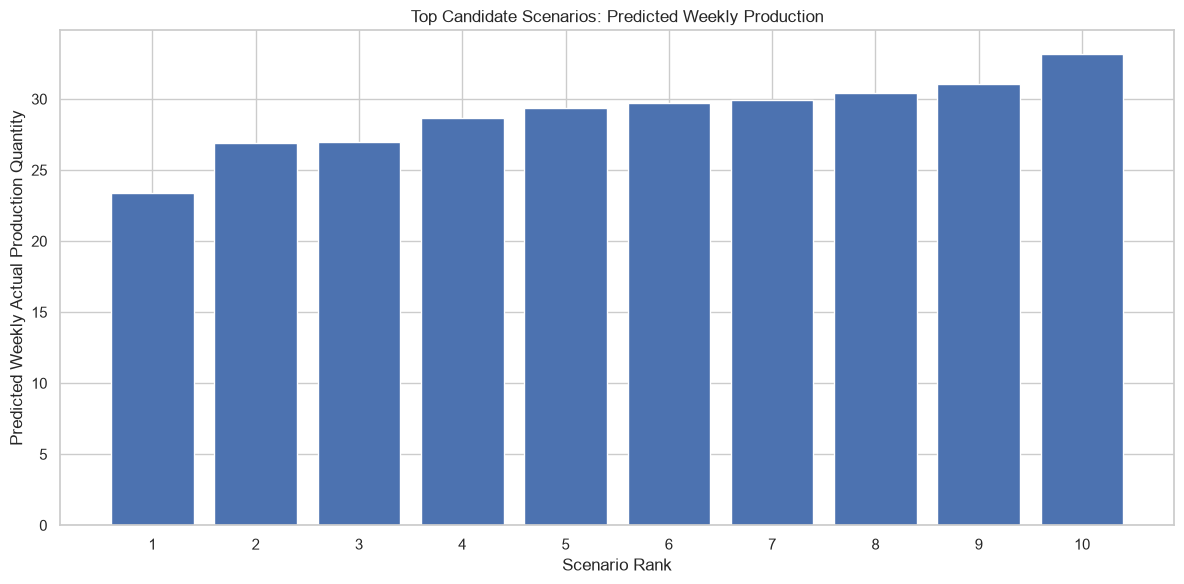

In [14]:
top_scenarios = ranked_scenarios.head(10).copy()

plt.figure(figsize=(12, 6))

plt.bar(
    top_scenarios["scenario_rank"].astype(str),
    top_scenarios["predicted_actual_qty"]
)

if planned_qty is not None:
    plt.axhline(
        y=planned_qty,
        linestyle="--",
        label="Planned Production Target"
    )
    plt.legend()

plt.xlabel("Scenario Rank")
plt.ylabel("Predicted Weekly Actual Production Quantity")
plt.title("Top Candidate Scenarios: Predicted Weekly Production")
plt.tight_layout()
plt.show()

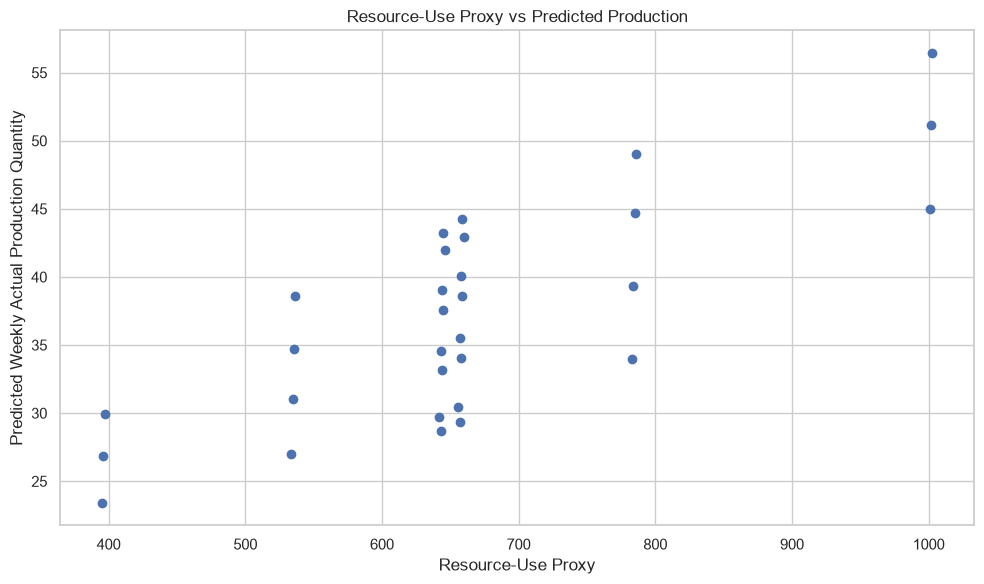

In [15]:

# Visualise resource use against the production gap when a target exists.
# Without a planned target, visualise resource use against predicted production.

plt.figure(figsize=(10, 6))

if "absolute_gap" in ranked_scenarios.columns:

    plt.scatter(
        ranked_scenarios["resource_use_proxy"],
        ranked_scenarios["absolute_gap"]
    )

    plt.ylabel("Absolute Production Gap")
    plt.title("Resource-Use Proxy vs Absolute Production Gap")

else:

    plt.scatter(
        ranked_scenarios["resource_use_proxy"],
        ranked_scenarios["predicted_actual_qty"]
    )

    plt.ylabel("Predicted Weekly Actual Production Quantity")
    plt.title("Resource-Use Proxy vs Predicted Production")

plt.xlabel("Resource-Use Proxy")
plt.tight_layout()
plt.show()

### 6.16 Inspect the Baseline Prediction

The baseline prediction represents the model's estimate for the selected historical production context before the candidate resource configurations are compared.

Comparing the baseline prediction with the observed historical `actual_qty` helps identify whether the model's output is plausible for that record. A single comparison is not a substitute for independent test-set evaluation.

If the baseline prediction is far from the observed value, review the model's input features, preprocessing pipeline, target scale, and model evaluation results before interpreting the optimisation scenarios.

In [16]:
# Compare the baseline prediction with the observed actual quantity

# Get the observed actual quantity for the selected baseline row
baseline_actual = float(
    df.iloc[baseline_index]["actual_qty"]
)

# Generate the prediction using the trained model
baseline_predicted = float(
    np.asarray(
        production_model.predict(baseline_features)
    ).reshape(-1)[0]
)

# Calculate prediction error
baseline_error = baseline_predicted - baseline_actual

# Display the results
print("Baseline Production Comparison")
print("-" * 40)
print("Observed actual quantity:", round(baseline_actual, 2))
print("Predicted actual quantity:", round(baseline_predicted, 2))
print("Prediction error:", round(baseline_error, 2))
print("Absolute prediction error:", round(abs(baseline_error), 2))

Baseline Production Comparison
----------------------------------------
Observed actual quantity: 24.0
Predicted actual quantity: 29.37
Prediction error: 5.37
Absolute prediction error: 5.37


### 6.18 Export the Results

The baseline prediction and ranked candidate scenarios are exported as CSV files for further inspection and future integration with the Streamlit decision-support dashboard.

The exported results are preliminary model outputs. They should not be interpreted as approved production instructions until the target, prediction quality, resource constraints, and ranking objective have been validated.

In [17]:
from pathlib import Path

# Create an output directory in the project root
output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the baseline prediction summary
baseline_summary = pd.DataFrame({
    "observed_actual_qty": [baseline_actual],
    "predicted_actual_qty": [baseline_predicted],
    "prediction_error": [baseline_error],
    "absolute_prediction_error": [abs(baseline_error)],
    "planned_qty": [planned_qty],
    "target_tolerance": [target_tolerance]
})

baseline_path = output_dir / "notebook6_baseline_prediction.csv"
baseline_summary.to_csv(baseline_path, index=False)

# Save all ranked candidate scenarios
ranked_path = output_dir / "notebook6_ranked_scenarios.csv"
ranked_scenarios.to_csv(ranked_path, index=False)

print("Baseline summary saved to:", baseline_path.resolve())
print("Ranked scenarios saved to:", ranked_path.resolve())

Baseline summary saved to: C:\Production-DI Leather\production-DI\notebooks\outputs\notebook6_baseline_prediction.csv
Ranked scenarios saved to: C:\Production-DI Leather\production-DI\notebooks\outputs\notebook6_ranked_scenarios.csv


### 6.20 Summary, Interpretation and Limitations

This notebook demonstrates a preliminary prescriptive optimisation workflow using the trained production prediction model. Candidate configurations are generated by varying the number of workers, working hours, and machines while retaining the other baseline context and recalculating the engineered resource-ratio features.

The scenarios are ranked according to whether their predicted production falls within the specified target tolerance, their absolute gap from the target, and a simple resource-use proxy.

The following limitations must be considered:

1. **Prediction validity:** Candidate predictions must be consistent with the historical target scale and the model's independent evaluation results.
2. **Target validity:** The planned quantity must correspond to the same production unit, product context, and comparable period as `actual_qty`.
3. **Operational constraints:** The candidate resource values are provisional search values, not confirmed factory capacity limits.
4. **Ranking objective:** The resource-use proxy is not a financial cost. A production objective based on actual labour, machine, overtime, and other relevant costs would be more meaningful if those data become available.
5. **Causal limitations:** The model estimates production from learned historical patterns. Its predictions do not prove that changing a resource allocation will cause the predicted change in output.
6. **Operational approval:** Final candidate configurations require validation by factory experts before implementation.

The next stage is to validate the baseline and candidate predictions, review the independent model evaluation, and refine the optimisation objective and operational constraints. Once these checks are satisfactory, the validated workflow can be integrated into the planned Streamlit decision-support dashboard.